# 10 · Error Analysis & Explainability (CNN vs ViT)

**Research task:** Five-class tomato leaf disease diagnosis and lab-to-field generalization.

## Goal

Understand **which field images fail, which classes are affected, and what image regions the two final mixed-domain models attend to**. This notebook does **not train or select a model**. It reuses the fixed predictions from `09_final_model_comparison.ipynb` and loads only two fixed checkpoints for visualization.

**Important methodological boundary:** All analyses use **Field Dev (92 PlantDoc images)**, which has already been used for checkpoint selection. This is exploratory error analysis, **not independent validation**. The original 47-image Field Test is deliberately never loaded.

**Outputs:** Paired error tables, class-level failures, high-confidence errors, a sample gallery, CNN Grad-CAM, ViT last-block CLS attention maps, and a manual review template.

## 1 · Environment and inputs.

In [1]:
# %pip install -q "timm==1.0.26" datasets imagehash scikit-learn pandas matplotlib pillow

In [2]:
from pathlib import Path
import gc, hashlib, json, os, subprocess, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from datasets import load_dataset
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report
from torchvision.models import ResNet18_Weights, resnet18
from torch import nn

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
IN_COLAB = ("google.colab" in sys.modules) or bool(os.environ.get("COLAB_RELEASE_TAG"))

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
    if PROJECT_ROOT.exists():
        subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
    DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-diagnosis")
    PRED_DIR = DRIVE_ROOT / "final_comparison_development"
    OUTPUT_ROOT = DRIVE_ROOT / "error_analysis_development"
else:
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    PROJECT_ROOT = next((p for p in candidates
                         if (p / "data" / "splits" / "field_dev.csv").is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError("Open VS Code from the repository root (or its notebooks/ folder).")
    DRIVE_ROOT = None
    PRED_DIR = PROJECT_ROOT / "outputs" / "final_comparison_development"
    OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "error_analysis_development"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_ROOT / "case_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sys.path.insert(0, str(PROJECT_ROOT))
GIT_SHA = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True
).strip()
print("Repository:", PROJECT_ROOT, "| Commit:", GIT_SHA)
print("Device:", DEVICE, "| Predictions:", PRED_DIR, "| Output:", OUTPUT_ROOT)

Mounted at /content/drive
Repository: /content/plant-disease-diagnosis | Commit: 2525f2fc6ee487a3c28abc16f76933acdb2d8291
Device: cpu | Predictions: /content/drive/MyDrive/plant-disease-diagnosis/final_comparison_development | Output: /content/drive/MyDrive/plant-disease-diagnosis/error_analysis_development


### Input contract

Step 9 saves four prediction CSVs in a fixed order. We verify `row_id`, true labels, classes, and scores against the **current verified manifest** before doing anything else. Never join predictions based on row position alone.

If running locally, copy `predictions_model1_field_dev.csv` through `predictions_model4_field_dev.csv` from your Step 9 Google Drive output to `outputs/final_comparison_development/`.

In [3]:
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
MANIFEST = SPLITS_DIR / "field_dev.csv"
LABEL_MAP = json.loads((SPLITS_DIR / "label_map.json").read_text(encoding="utf-8"))
CLASS_NAMES = [key for key, idx in sorted(LABEL_MAP.items(), key=lambda kv: kv[1])]
assert len(CLASS_NAMES) == 5 and sorted(LABEL_MAP.values()) == list(range(5))
field = pd.read_csv(MANIFEST)
assert len(field) == 92, f"Expected verified 92-image Field Dev; got {len(field)}."
assert field.row_id.is_unique and (field.source == "plantdoc").all()
assert (field.class_name.map(LABEL_MAP) == field.label_id).all()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

FIELD_SHA = sha256_file(MANIFEST)
protocol_path = PRED_DIR / "comparison_protocol.json"
if protocol_path.is_file():
    protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    assert protocol["manifests_sha256"]["field_dev"] == FIELD_SHA, (
        "Step 9 predictions use a different Field Dev manifest!"
    )
    assert protocol.get("field_test_inference_performed") is False
else:
    print("Note: comparison_protocol.json not found; row_id/label checks will still be enforced.")
print("Field Dev:", len(field), "images; SHA256:", FIELD_SHA)

Field Dev: 92 images; SHA256: 2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9


In [4]:
MODEL_FILES = {
    "resnet_base": (1, "ResNet18 · Lab baseline"),
    "vit_base": (2, "ViT-Small · Lab baseline"),
    "resnet_mixed": (3, "ResNet18 · Geometric + Mixed"),
    "vit_mixed": (4, "ViT-Small · Mixed"),
}
paired = field[["row_id", "class_name", "original_class", "label_id"]].copy()

for key, (index, model_name) in MODEL_FILES.items():
    path = PRED_DIR / f"predictions_model{index}_field_dev.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run Step 9 or copy its saved prediction CSVs.")
    pred = pd.read_csv(path)
    assert len(pred) == len(field) and pred.row_id.is_unique
    assert set(pred.row_id) == set(field.row_id)
    assert set(pred["model"]) == {model_name}, (path, pred["model"].unique())
    assert set(pred["partition"]) == {"field_dev"}
    pred = pred.set_index("row_id").loc[paired.row_id].reset_index()
    assert np.array_equal(pred.label_id.to_numpy(), paired.label_id.to_numpy()), key
    assert pred.class_name.tolist() == paired.class_name.tolist(), key
    assert np.all(pred.predicted_label_id.between(0, 4))
    assert np.all((pred.confidence >= 0) & (pred.confidence <= 1))
    assert (pred.predicted_label_id == pred.label_id).equals(pred.correct.astype(bool))
    paired[f"{key}_prediction"] = pred.predicted_class.to_numpy()
    paired[f"{key}_pred_id"] = pred.predicted_label_id.to_numpy()
    paired[f"{key}_confidence"] = pred.confidence.to_numpy()
    paired[f"{key}_correct"] = pred.correct.astype(bool).to_numpy()

paired["outcome"] = np.select(
    [paired.resnet_mixed_correct & paired.vit_mixed_correct,
     paired.resnet_mixed_correct & ~paired.vit_mixed_correct,
     ~paired.resnet_mixed_correct & paired.vit_mixed_correct],
    ["both_correct", "resnet_only", "vit_only"], default="both_wrong"
)
paired.to_csv(OUTPUT_ROOT / "paired_field_dev_errors.csv", index=False)
print("Paired predictions verified against Field Dev:")
print(paired.outcome.value_counts().to_string())

Paired predictions verified against Field Dev:
outcome
both_wrong      36
both_correct    24
resnet_only     19
vit_only        13


## 2 · Which model is wrong, and on which disease?

Start with paired predictions: a correct/incorrect disagreement on the **same photograph** is more informative than comparing two aggregate F1 scores. Pay particular attention to cases where **both models are wrong**. These examples are candidates for label review and further field data collection.

,model,correct,accuracy,macro_f1
0,ResNet18 · Lab baseline,30,0.3261,0.2355
1,ViT-Small · Lab baseline,37,0.4022,0.2677
2,ResNet18 · Geometric + Mixed,43,0.4674,0.4459
3,ViT-Small · Mixed,37,0.4022,0.3872


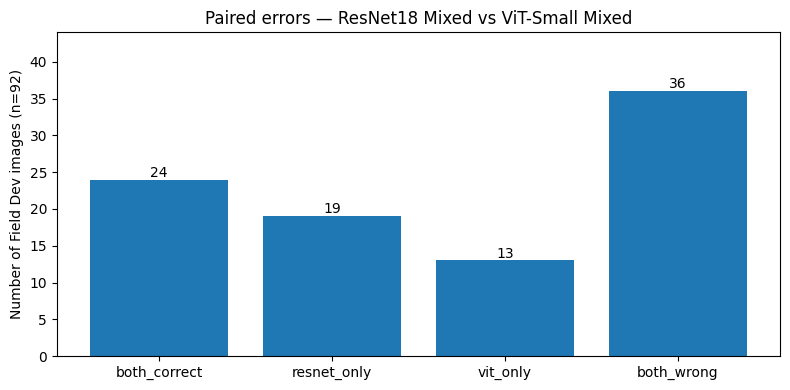

In [5]:
score_rows = []
for key, (_, name) in MODEL_FILES.items():
    y_true = paired.label_id.to_numpy()
    y_pred = paired[f"{key}_pred_id"].to_numpy()
    score_rows.append({"model": name, "correct": int((y_true == y_pred).sum()),
                       "accuracy": accuracy_score(y_true, y_pred),
                       "macro_f1": f1_score(y_true, y_pred, labels=list(range(5)),
                                            average="macro", zero_division=0)})
score_df = pd.DataFrame(score_rows)
score_df.to_csv(OUTPUT_ROOT / "reproduced_field_dev_metrics.csv", index=False)
display(score_df.round(4))

outcome_order = ["both_correct", "resnet_only", "vit_only", "both_wrong"]
counts = paired.outcome.value_counts().reindex(outcome_order, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values)
ax.set(title="Paired errors — ResNet18 Mixed vs ViT-Small Mixed",
       ylabel="Number of Field Dev images (n=92)", ylim=(0, max(counts.values)+8))
for i, v in enumerate(counts.values):
    ax.text(i, v + .4, str(v), ha="center")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "paired_outcomes.png", dpi=160)
plt.show()
plt.close(fig)

,images,resnet_correct,vit_correct,both_wrong,resnet_recall,vit_recall
class_name,,,,,,
Healthy,11,6,6,2,0.545,0.545
Early Blight,16,5,4,8,0.312,0.250
Late Blight,20,11,9,5,0.550,0.450
Bacterial Spot,18,3,3,13,0.167,0.167
Septoria Leaf Spot,27,18,15,8,0.667,0.556


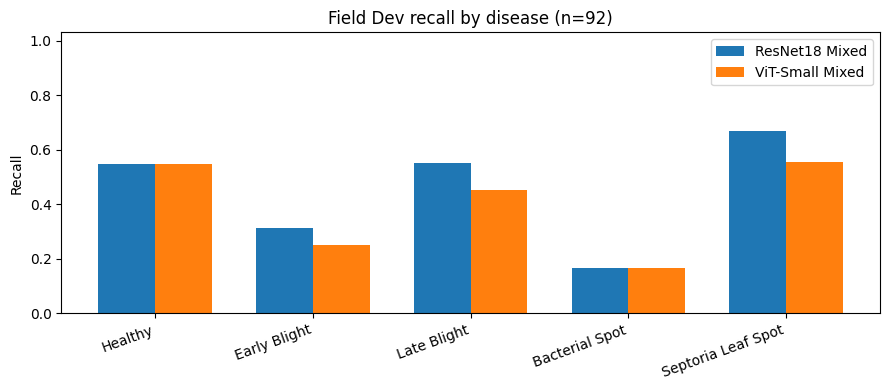

In [6]:
by_class = (paired.groupby("class_name", observed=False)
            .agg(images=("row_id", "size"),
                 resnet_correct=("resnet_mixed_correct", "sum"),
                 vit_correct=("vit_mixed_correct", "sum"),
                 both_wrong=("outcome", lambda s: int((s == "both_wrong").sum())))
            .reindex(CLASS_NAMES))
by_class["resnet_recall"] = by_class.resnet_correct / by_class.images
by_class["vit_recall"] = by_class.vit_correct / by_class.images
by_class.to_csv(OUTPUT_ROOT / "field_dev_error_by_class.csv")
display(by_class.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(CLASS_NAMES))
ax.bar(xs - .18, by_class.resnet_recall, width=.36, label="ResNet18 Mixed")
ax.bar(xs + .18, by_class.vit_recall, width=.36, label="ViT-Small Mixed")
ax.set_xticks(xs, CLASS_NAMES, rotation=20, ha="right")
ax.set_ylim(0, 1.03)
ax.set_ylabel("Recall")
ax.set_title("Field Dev recall by disease (n=92)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "field_recall_by_class.png", dpi=160)
plt.show()
plt.close(fig)

### High-confidence errors are still errors

Softmax confidence is **not a calibrated probability of being correct**. We identify wrong predictions with confidence ≥ 0.90 to prioritize manual inspection. Do not interpret a high confidence score as medical or agronomic certainty.

In [7]:
HIGH_CONFIDENCE = 0.90
for key in ("resnet_mixed", "vit_mixed"):
    wrong = ~paired[f"{key}_correct"]
    high = wrong & (paired[f"{key}_confidence"] >= HIGH_CONFIDENCE)
    print(f"{key}: {wrong.sum()}/{len(paired)} errors; "
          f"{high.sum()} high-confidence errors (threshold={HIGH_CONFIDENCE})")

high_error = paired.loc[
    ((~paired.resnet_mixed_correct) & (paired.resnet_mixed_confidence >= HIGH_CONFIDENCE)) |
    ((~paired.vit_mixed_correct) & (paired.vit_mixed_confidence >= HIGH_CONFIDENCE)),
    ["row_id", "class_name", "resnet_mixed_prediction", "resnet_mixed_confidence",
     "vit_mixed_prediction", "vit_mixed_confidence", "outcome"]
].copy()
high_error.to_csv(OUTPUT_ROOT / "high_confidence_errors.csv", index=False)
display(high_error.sort_values("row_id").head(15).round(3))

resnet_mixed: 49/92 errors; 3 high-confidence errors (threshold=0.9)
vit_mixed: 55/92 errors; 9 high-confidence errors (threshold=0.9)


,row_id,class_name,resnet_mixed_prediction,resnet_mixed_confidence,vit_mixed_prediction,vit_mixed_confidence,outcome
3,1580,Early Blight,Bacterial Spot,0.706,Bacterial Spot,0.941,both_wrong
7,1596,Early Blight,Late Blight,0.733,Late Blight,0.958,both_wrong
15,1629,Early Blight,Early Blight,0.419,Septoria Leaf Spot,0.952,resnet_only
24,1688,Septoria Leaf Spot,Bacterial Spot,0.915,Bacterial Spot,0.927,both_wrong
61,1891,Bacterial Spot,Bacterial Spot,0.509,Healthy,0.935,resnet_only
62,1899,Bacterial Spot,Septoria Leaf Spot,0.966,Septoria Leaf Spot,0.997,both_wrong
65,1909,Bacterial Spot,Septoria Leaf Spot,0.925,Septoria Leaf Spot,0.953,both_wrong
83,1994,Late Blight,Septoria Leaf Spot,0.387,Septoria Leaf Spot,0.970,both_wrong
91,2025,Late Blight,Healthy,0.322,Healthy,0.904,both_wrong


## 3 · Select representative mistakes

A systematic, reproducible gallery is preferable to selecting only attractive examples. We sample jointly wrong, ResNet-only, ViT-only cases and at least one Bacterial Spot failure where available. These cases are **illustrative, not a random sample of all failures**.

In [8]:
selected_rows, seen = [], set()
def add_cases(frame, reason, limit):
    for _, row in frame.iterrows():
        row_id = int(row.row_id)
        if row_id not in seen and len([r for r in selected_rows if r["reason"] == reason]) < limit:
            selected_rows.append({"row_id": row_id, "reason": reason})
            seen.add(row_id)

priority = paired.assign(
    error_confidence=paired[["resnet_mixed_confidence", "vit_mixed_confidence"]].max(axis=1)
).sort_values(["error_confidence", "row_id"], ascending=[False, True])
add_cases(priority[priority.outcome == "both_wrong"], "both_wrong", 3)
add_cases(priority[priority.outcome == "resnet_only"], "resnet_only", 2)
add_cases(priority[priority.outcome == "vit_only"], "vit_only", 2)
add_cases(priority[(priority.class_name == "Bacterial Spot") &
                   (priority.outcome != "both_correct")], "bacterial_spot", 1)

selected = pd.DataFrame(selected_rows).merge(paired, on="row_id", validate="one_to_one")
assert len(selected) <= 8 and selected.row_id.is_unique
selected.to_csv(OUTPUT_ROOT / "selected_error_cases.csv", index=False)
display(selected[["row_id", "reason", "class_name", "resnet_mixed_prediction",
                  "vit_mixed_prediction", "resnet_mixed_confidence", "vit_mixed_confidence"]].round(3))

,row_id,reason,class_name,resnet_mixed_prediction,vit_mixed_prediction,resnet_mixed_confidence,vit_mixed_confidence
0,1899,both_wrong,Bacterial Spot,Septoria Leaf Spot,Septoria Leaf Spot,0.966,0.997
1,1994,both_wrong,Late Blight,Septoria Leaf Spot,Septoria Leaf Spot,0.387,0.970
2,1596,both_wrong,Early Blight,Late Blight,Late Blight,0.733,0.958
3,1812,resnet_only,Healthy,Healthy,Late Blight,0.959,0.654
4,1629,resnet_only,Early Blight,Early Blight,Septoria Leaf Spot,0.419,0.952
5,1602,vit_only,Early Blight,Late Blight,Early Blight,0.752,0.987
6,1804,vit_only,Healthy,Bacterial Spot,Healthy,0.501,0.956
7,1909,bacterial_spot,Bacterial Spot,Septoria Leaf Spot,Septoria Leaf Spot,0.925,0.953


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  516MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2578 [00:00<?, ? examples/s]

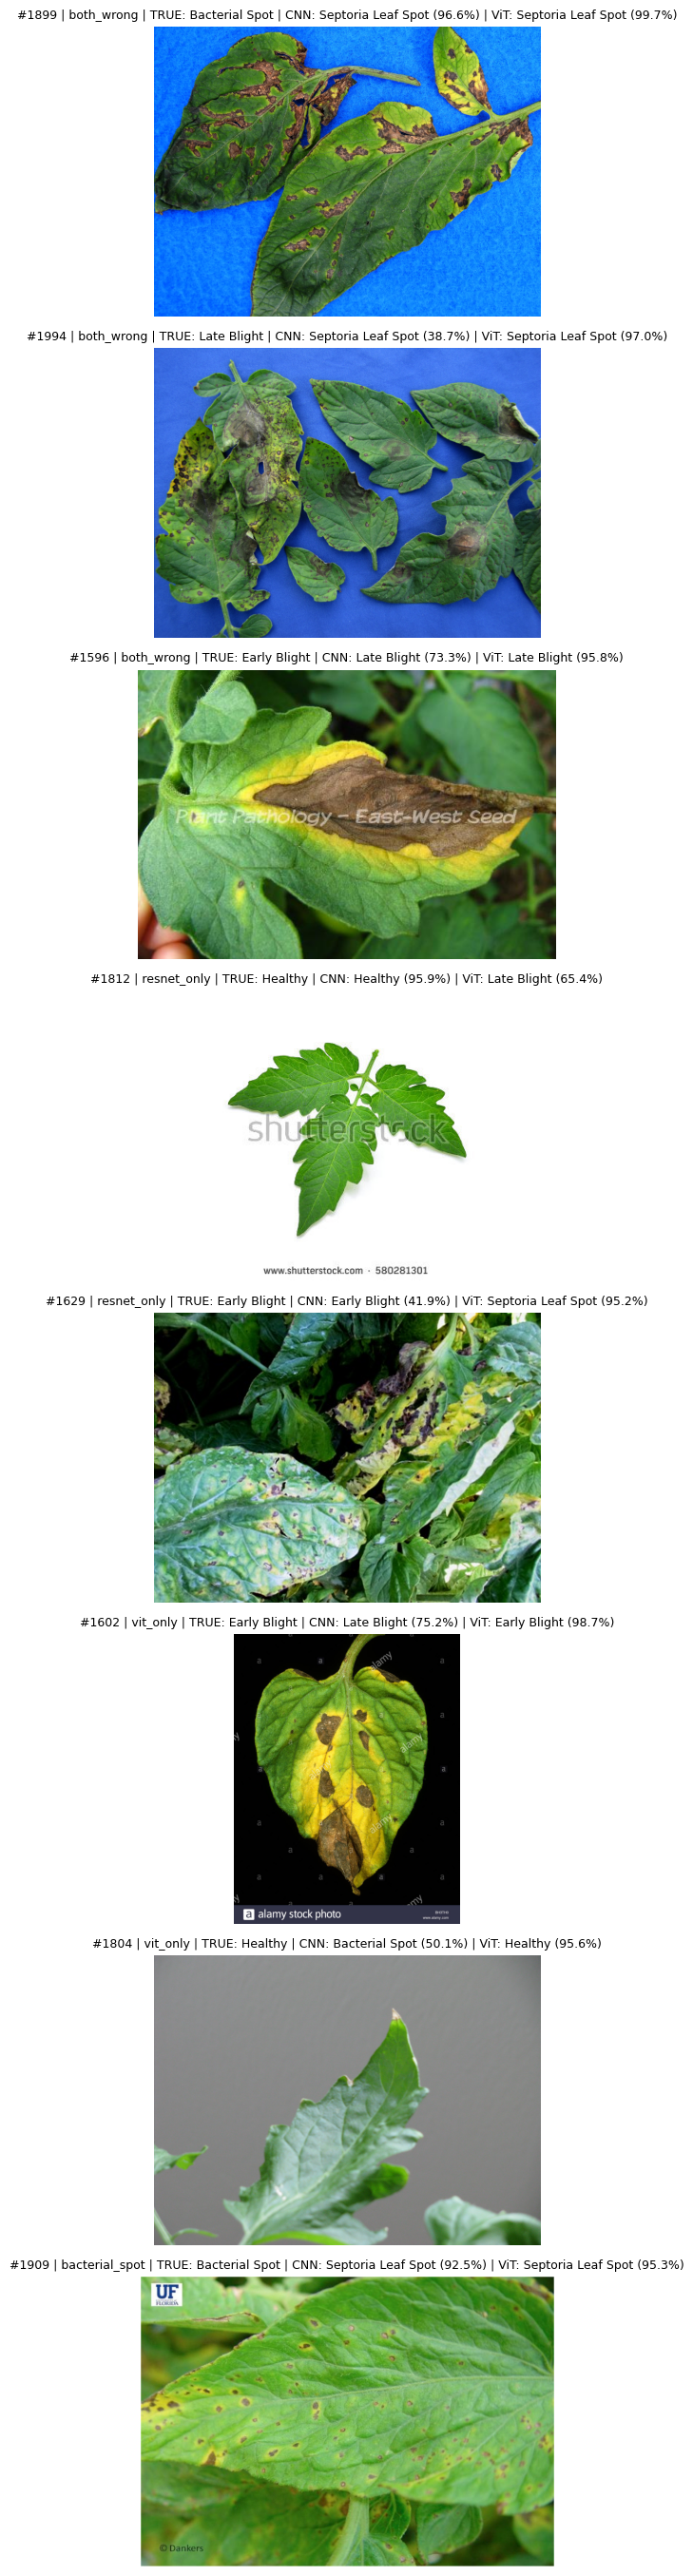

In [9]:
# Load only PlantDoc; do not load the Field Test split.
source = load_dataset("geraldmc/plantdoc-full", revision="v0.1.0", split="train")

def fetch_original(row_id):
    sample = source[int(row_id)]
    expected = field.set_index("row_id").loc[int(row_id), "original_class"]
    assert sample["class_label"] == expected, (
        f"Source row ordering or label changed for row_id={row_id}!"
    )
    return sample["image"].convert("RGB")

n = len(selected)
fig, axes = plt.subplots(n, 1, figsize=(11, 3.4 * n), squeeze=False)
for i, row in selected.iterrows():
    axes[i, 0].imshow(fetch_original(row.row_id))
    axes[i, 0].axis("off")
    axes[i, 0].set_title(
        f'#{row.row_id} | {row.reason} | TRUE: {row.class_name} | '
        f'CNN: {row.resnet_mixed_prediction} ({row.resnet_mixed_confidence:.1%}) | '
        f'ViT: {row.vit_mixed_prediction} ({row.vit_mixed_confidence:.1%})', fontsize=9
    )
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "selected_error_gallery.png", dpi=135)
plt.show()
plt.close(fig)

## 4 · Explainability: what image regions receive attention?

For the **same selected images**:

- **ResNet18 Grad-CAM:** the image regions whose final convolutional feature maps contribute most to the **predicted class score**.
- **ViT CLS attention:** average attention from the class token to image patches in the **last transformer block**.

These visualize **different mechanisms**. They are exploratory, not equivalent measurements, and do **not prove** that the model relies on the disease lesion. Bright regions can reflect background cues, blur, and attention artifacts. Evaluate them qualitatively against the visible symptoms.

**Checkpoint requirement:** Mixed ResNet18 and Mixed ViT checkpoints must be exactly those from Step 9. If running locally, download them from Google Drive and edit `CHECKPOINTS` in the next cell.

In [10]:
if IN_COLAB:
    CHECKPOINTS = {
        "resnet_mixed": DRIVE_ROOT / "mixed_domain_verified/R2_resnet_geometric/mixed_domain_best.pt",
        "vit_mixed": DRIVE_ROOT / "mixed_domain_verified/V1_vit_small/mixed_domain_best.pt",
        "vit_source": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt",
    }
else:
    # Download the exact Step 9 checkpoints to these paths on your Mac.
    CHECKPOINTS = {
        "resnet_mixed": PROJECT_ROOT / "models" / "resnet18_geometric_mixed_best.pt",
        "vit_mixed": PROJECT_ROOT / "models" / "vit_small_mixed_best.pt",
        "vit_source": PROJECT_ROOT / "models" / "vit_small_lab_best.pt",
    }

for name, ckpt in CHECKPOINTS.items():
    assert ckpt.is_file(), f"Missing checkpoint: {ckpt}. Copy it from Google Drive or edit CHECKPOINTS."

res_state = torch.load(CHECKPOINTS["resnet_mixed"], map_location="cpu", weights_only=True)
vit_state = torch.load(CHECKPOINTS["vit_mixed"], map_location="cpu", weights_only=True)
vit_original = torch.load(CHECKPOINTS["vit_source"], map_location="cpu", weights_only=True)
for ckpt in (res_state, vit_state, vit_original):
    assert list(ckpt["class_names"]) == CLASS_NAMES
for state in (res_state, vit_state):
    assert state["field_dev_sha256"] == FIELD_SHA, "Checkpoint was selected on a different Field Dev split!"
assert res_state["architecture"] == "resnet18"
assert vit_state["architecture"] == "vit_small_patch16_224.augreg_in1k"
assert vit_original["architecture"] == vit_state["architecture"]
assert vit_state["source_checkpoint_sha256"] == sha256_file(CHECKPOINTS["vit_source"])
VIT_CONFIG = vit_original["preprocessing_config"]
print("Both fixed mixed-domain checkpoints match the verified Field Dev manifest.")

Both fixed mixed-domain checkpoints match the verified Field Dev manifest.


### 4A · Grad-CAM on ResNet18

We compute class-specific Grad-CAM for the model's own predicted class. Overlays are drawn on the **actual model input after preprocessing**, avoiding misalignment between transformed images and heatmaps.

In [11]:
resnet_transform = ResNet18_Weights.IMAGENET1K_V1.transforms()

resnet = resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, len(CLASS_NAMES))
resnet.load_state_dict(res_state["model_state_dict"], strict=True)
resnet.to(DEVICE).eval()

def denorm_image(tensor, mean, std):
    img = tensor.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(img * np.asarray(std) + np.asarray(mean), 0, 1)

def heat_overlay(img, heat):
    colored = plt.colormaps["inferno"](heat)[..., :3]
    return (0.58 * img + 0.42 * colored).clip(0, 1)

def gradcam_resnet(image):
    tensor = resnet_transform(image).unsqueeze(0).to(DEVICE)
    holder = {}
    def capture(_, __, activation):
        holder["activation"] = activation
        activation.retain_grad()
    handle = resnet.layer4[-1].register_forward_hook(capture)
    try:
        resnet.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = resnet(tensor)
            predicted = int(logits.argmax(dim=1).item())
            logits[0, predicted].backward()
            features = holder["activation"].detach()
            grad = holder["activation"].grad.detach()
            weights = grad.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((features * weights).sum(dim=1, keepdim=True))
            cam = F.interpolate(cam, size=tensor.shape[-2:], mode="bilinear", align_corners=False)
            cam = cam[0, 0].cpu().numpy()
            cam = (cam - cam.min()) / max(cam.max() - cam.min(), 1e-8)
        unnormalized = denorm_image(tensor[0], resnet_transform.mean, resnet_transform.std)
        return predicted, unnormalized, cam
    finally:
        handle.remove()

resnet_maps = {}
for row in selected.itertuples():
    img = fetch_original(row.row_id)
    pred, model_input, heat = gradcam_resnet(img)
    assert pred == int(row.resnet_mixed_pred_id), f"CNN prediction mismatch for {row.row_id}"
    resnet_maps[int(row.row_id)] = {"input": model_input, "heat": heat}
print("Generated", len(resnet_maps), "ResNet18 Grad-CAM maps.")
del resnet, res_state
gc.collect()
if DEVICE.type == "cuda": torch.cuda.empty_cache()

Generated 8 ResNet18 Grad-CAM maps.


### 4B · ViT last-block CLS-to-patch attention

We read the input to the final self-attention layer and compute its softmax attention explicitly. This works even when timm uses *fused attention*, which may bypass ordinary attention-dropout hooks. **Attention is not the same as causal feature attribution.**

In [12]:
vit_transform = timm.data.create_transform(**VIT_CONFIG, is_training=False)
vit = timm.create_model("vit_small_patch16_224.augreg_in1k", pretrained=False,
                        num_classes=len(CLASS_NAMES))
vit.load_state_dict(vit_state["model_state_dict"], strict=True)
vit.to(DEVICE).eval()

def last_block_cls_attention(image):
    tensor = vit_transform(image).unsqueeze(0).to(DEVICE)
    last_attn = vit.blocks[-1].attn
    cache = {}
    def save_pre_attn(_, args):
        cache["x"] = args[0].detach()
    handle = last_attn.register_forward_pre_hook(save_pre_attn)
    try:
        with torch.inference_mode():
            logits = vit(tensor)
            predicted = int(logits.argmax(dim=1).item())
            x = cache["x"]
            b, n, c = x.shape
            heads = last_attn.num_heads
            qkv = last_attn.qkv(x).reshape(b, n, 3, heads, c // heads).permute(2, 0, 3, 1, 4)
            q, k = last_attn.q_norm(qkv[0]), last_attn.k_norm(qkv[1])
            attention = ((q * last_attn.scale) @ k.transpose(-2, -1)).softmax(dim=-1)
            prefix_tokens = getattr(vit, "num_prefix_tokens", 1)
            h, w = vit.patch_embed.grid_size
            assert (prefix_tokens + h*w) == n, (prefix_tokens, h, w, n)
            # Average heads; class-token attention to spatial patches only.
            heat = attention[0, :, 0, prefix_tokens:].mean(dim=0).reshape(1, 1, h, w)
            heat = F.interpolate(heat, size=tensor.shape[-2:], mode="bilinear",
                                 align_corners=False)[0, 0].cpu().numpy()
            heat = (heat - heat.min()) / max(heat.max() - heat.min(), 1e-8)
        original_input = denorm_image(tensor[0], VIT_CONFIG["mean"], VIT_CONFIG["std"])
        return predicted, original_input, heat
    finally:
        handle.remove()

vit_maps = {}
for row in selected.itertuples():
    pred, model_input, heat = last_block_cls_attention(fetch_original(row.row_id))
    assert pred == int(row.vit_mixed_pred_id), f"ViT prediction mismatch for {row.row_id}"
    vit_maps[int(row.row_id)] = {"input": model_input, "heat": heat}
print("Generated", len(vit_maps), "ViT last-block attention maps.")
del vit, vit_state, vit_original
gc.collect()
if DEVICE.type == "cuda": torch.cuda.empty_cache()

Generated 8 ViT last-block attention maps.


## 5 · Side-by-side explanations and manual review

Review each row as **original photograph → ResNet18 Grad-CAM → ViT attention**, with the true and predicted classes in the title. Do not claim that bright regions definitively identify the disease; use expert label verification before making biological claims.

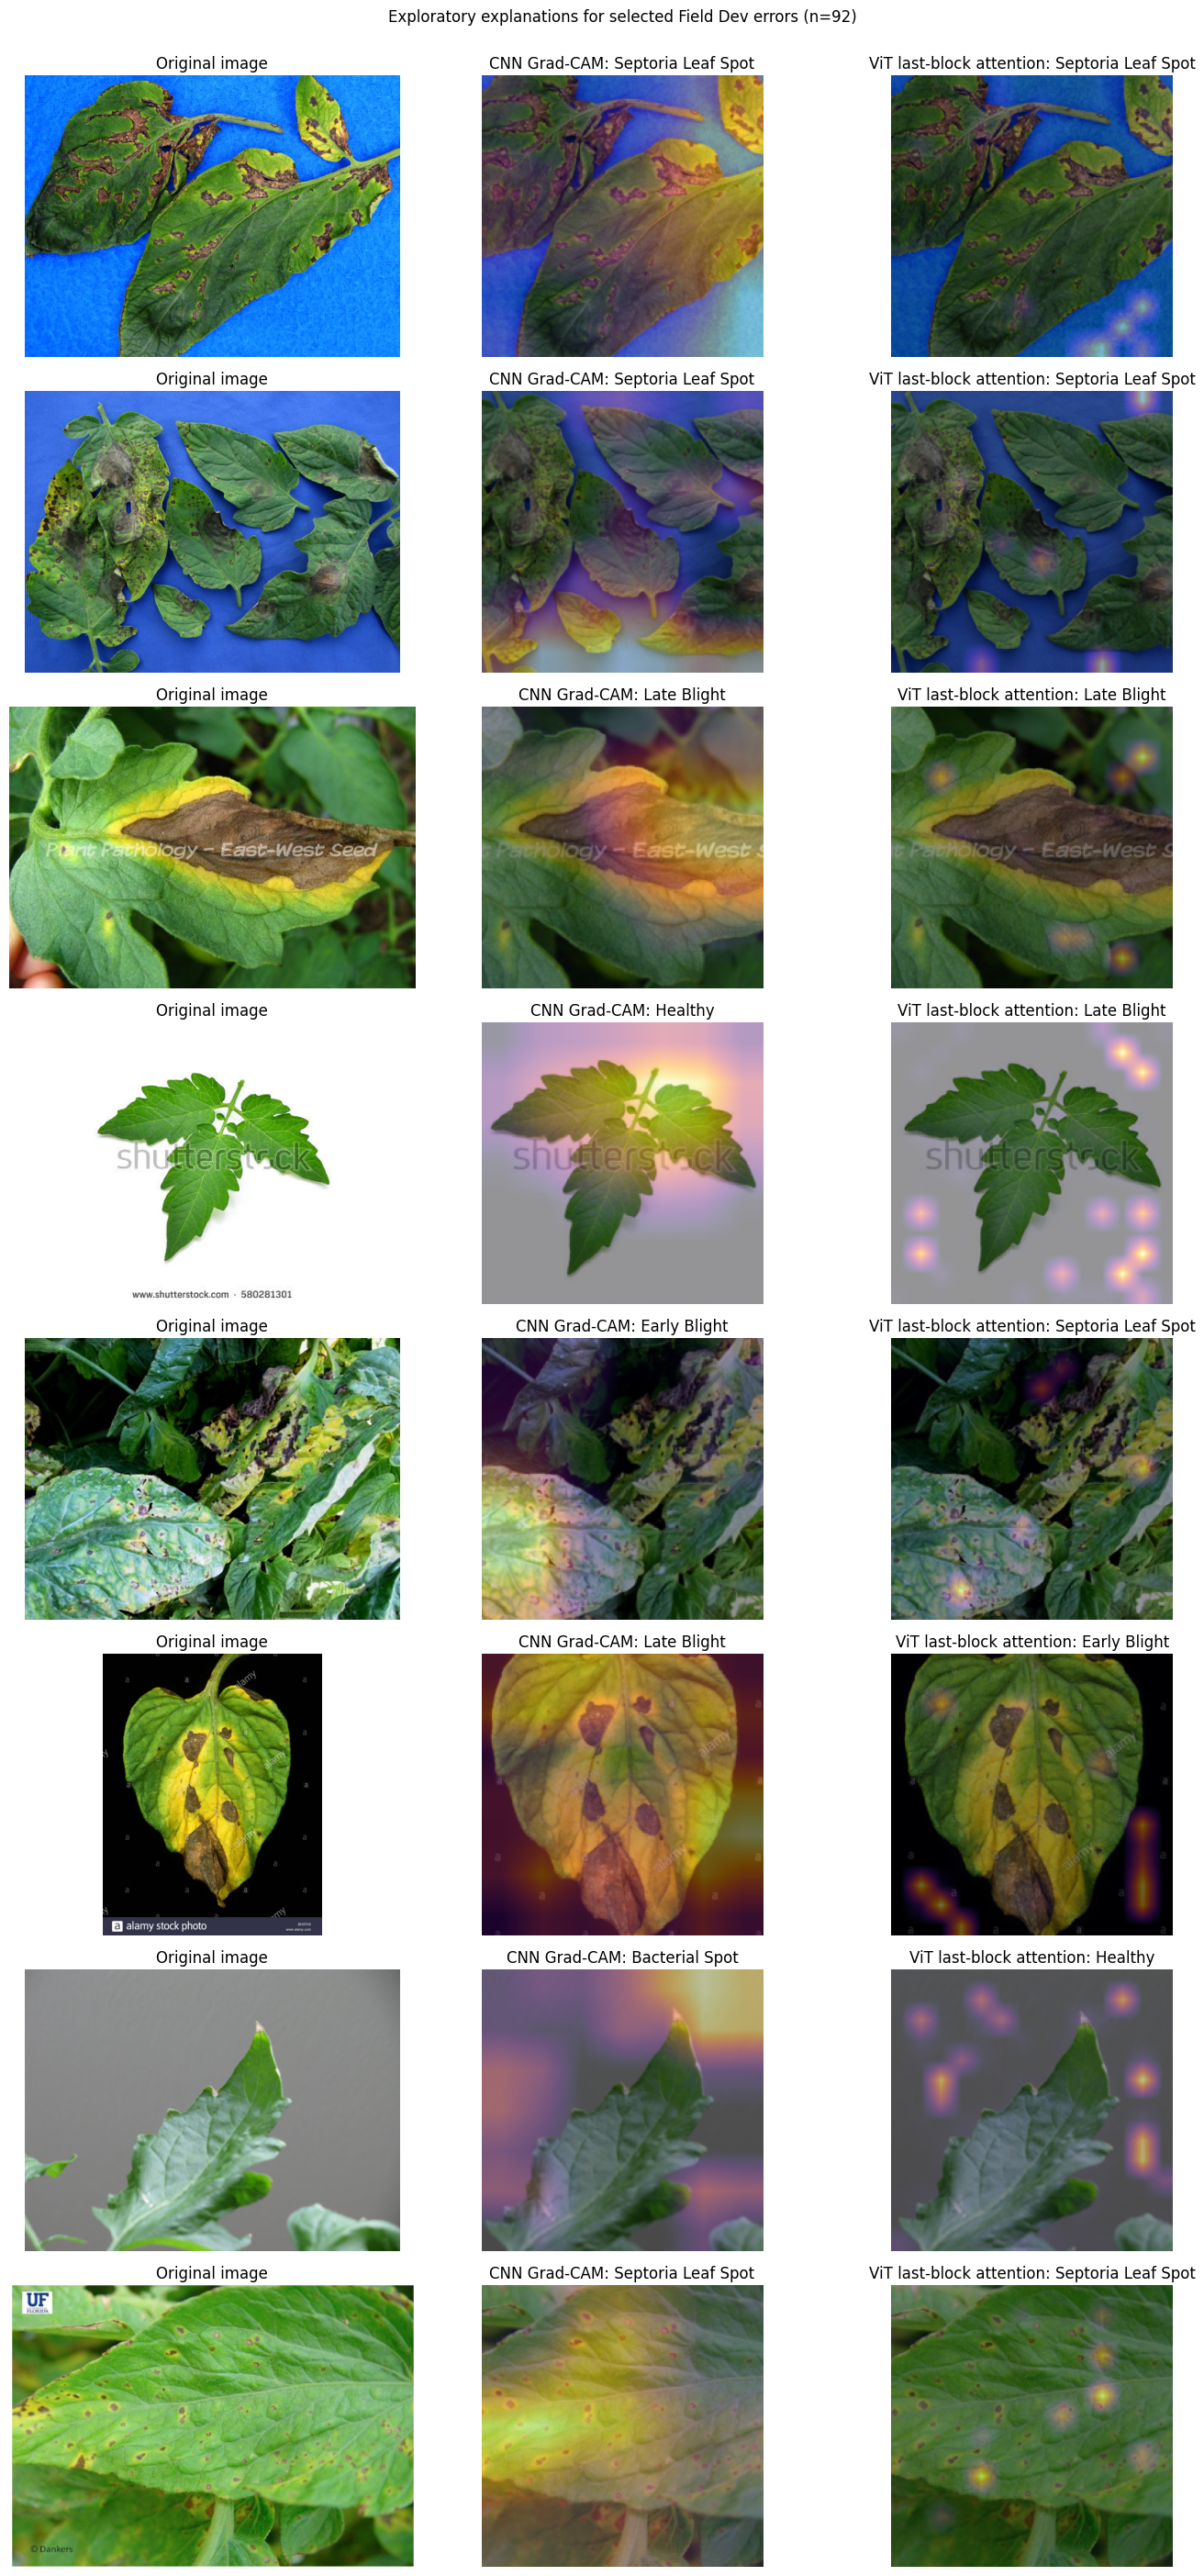

Review the PNG and complete manual_visual_review_template.csv; no interpretations are auto-filled.


In [13]:
fig, axes = plt.subplots(len(selected), 3, figsize=(14, 3.5 * len(selected)), squeeze=False)
for i, row in enumerate(selected.itertuples()):
    img = fetch_original(row.row_id)
    axes[i, 0].imshow(img); axes[i, 0].set_title("Original image")
    axes[i, 1].imshow(heat_overlay(resnet_maps[row.row_id]["input"],
                                  resnet_maps[row.row_id]["heat"]))
    axes[i, 1].set_title(f"CNN Grad-CAM: {row.resnet_mixed_prediction}")
    axes[i, 2].imshow(heat_overlay(vit_maps[row.row_id]["input"],
                                  vit_maps[row.row_id]["heat"]))
    axes[i, 2].set_title(f"ViT last-block attention: {row.vit_mixed_prediction}")
    for ax in axes[i]: ax.axis("off")
    axes[i, 0].set_ylabel(f"#{row.row_id} | {row.reason}\nTrue: {row.class_name}",
                          fontsize=10, rotation=0, labelpad=90, va="center")
fig.suptitle("Exploratory explanations for selected Field Dev errors (n=92)", y=1.001)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "cnn_gradcam_vs_vit_attention.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

review = selected[["row_id", "reason", "class_name", "resnet_mixed_prediction",
                   "vit_mixed_prediction"]].copy()
for name in ("visible_lesions", "cnn_focus_observation", "vit_focus_observation",
             "background_or_text_artifact", "suspected_label_issue", "reviewer_notes"):
    review[name] = ""
review.to_csv(OUTPUT_ROOT / "manual_visual_review_template.csv", index=False)
print("Review the PNG and complete manual_visual_review_template.csv; no interpretations are auto-filled.")

## 6 · Record, interpret, and report

After reviewing the figures, answer the following in the research report:

1. **Error patterns:** Which classes have the lowest recall? What kinds of errors are shared by CNN and ViT?
2. **Confidence:** How often are wrong predictions made with high softmax confidence? (Not a calibrated probability.)
3. **Visual evidence:** Do the highlighted regions overlap *visually plausible* symptoms, or do they include background/text? This is an inspection, not proof of mechanism.
4. **Dataset limitations:** PlantDoc has noisy and contradictory labels; known near-duplicates have been quarantined in the verified split, but residual issues may remain.
5. **Validation:** These are exploratory results on a previously used **Field Dev** set. A fresh, independently labeled Field Test is needed for confirmatory claims.

**Do not retrain or retune the four final checkpoints using the errors examined in this notebook.**

In [14]:
record = {
    "task": "Step 10 exploratory error analysis and explainability",
    "git_sha": GIT_SHA,
    "field_dev_sha256": FIELD_SHA,
    "images_in_field_dev": int(len(field)),
    "visualized_row_ids": [int(x) for x in selected.row_id],
    "class_names": CLASS_NAMES,
    "models": {key: value[1] for key, value in MODEL_FILES.items()},
    "explanations": ["ResNet18 Grad-CAM from final convolutional block",
                     "ViT last-block mean-head CLS attention to patch tokens"],
    "limitations": ["Field Dev was used for checkpoint selection",
                    "Attention is not causal feature attribution",
                    "Softmax confidence is uncalibrated",
                    "Label noise and missed near-duplicates may remain"],
    "used_original_field_test": False,
}
(OUTPUT_ROOT / "error_analysis_protocol.json").write_text(
    json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Saved output files:")
for path in sorted(OUTPUT_ROOT.rglob("*")):
    if path.is_file(): print(" -", path.relative_to(OUTPUT_ROOT))

Saved output files:
 - cnn_gradcam_vs_vit_attention.png
 - error_analysis_protocol.json
 - field_dev_error_by_class.csv
 - field_recall_by_class.png
 - high_confidence_errors.csv
 - manual_visual_review_template.csv
 - paired_field_dev_errors.csv
 - paired_outcomes.png
 - reproduced_field_dev_metrics.csv
 - selected_error_cases.csv
 - selected_error_gallery.png
